In [1]:
!pip install GEOparse gseapy -q

import pandas as pd
import numpy as np
import GEOparse

data = pd.read_csv("tnbc_data.csv", index_col=0)

y = data["label"]
X = data.drop(columns=["label"])

print("Dataset shape:", X.shape)
print("Labels:", y.value_counts().to_dict())

Dataset shape: (25, 54675)
Labels: {1.0: 24}


In [2]:
print("First 10 sample IDs:")
print(data.index[:10].tolist())

print("\nFirst 10 column names:")
print(data.columns[:10].tolist())

print("\nLabel column:")
print(data["label"].head(10))

print("\nAll files in Colab:")
import os
print(os.listdir("/content"))

First 10 sample IDs:
['GSM1974566', 'GSM1974567', 'GSM1974568', 'GSM1974569', 'GSM1974570', 'GSM1974571', 'GSM1974572', 'GSM1974573', 'GSM1974574', 'GSM1974575']

First 10 column names:
['1007_s_at', '1053_at', '117_at', '121_at', '1255_g_at', '1294_at', '1316_at', '1320_at', '1405_i_at', '1431_at']

Label column:
name
GSM1974566    1.0
GSM1974567    1.0
GSM1974568    1.0
GSM1974569    1.0
GSM1974570    1.0
GSM1974571    1.0
GSM1974572    1.0
GSM1974573    1.0
GSM1974574    1.0
GSM1974575    1.0
Name: label, dtype: float64

All files in Colab:
['.config', 'tnbc_data.csv', 'sample_data']


In [3]:
import os

for file in os.listdir("/content"):
    size = os.path.getsize("/content/" + file) / (1024 * 1024)
    print(file, "—", round(size, 2), "MB")

.config — 0.0 MB
tnbc_data.csv — 66.0 MB
sample_data — 0.0 MB


In [4]:
print("Label counts:")
print(data["label"].value_counts(dropna=False))

print("\nDataset shape:")
print(data.shape)

Label counts:
label
1.0    24
NaN     1
Name: count, dtype: int64

Dataset shape:
(25, 54676)


In [5]:
import pandas as pd

data = pd.read_csv("tnbc_data.csv", index_col=0)

print("Dataset shape:", data.shape)
print("\nLabel counts:")
print(data["label"].value_counts(dropna=False))

Dataset shape: (265, 54676)

Label counts:
label
1    198
0     67
Name: count, dtype: int64


In [6]:
y = data["label"]
X = data.drop(columns=["label"])

print("Before gene mapping:", X.shape)

gse = GEOparse.get_GEO("GSE76275", destdir="/content/")
gpl = gse.gpls["GPL570"].table

mapping_table = gpl[["ID", "Gene Symbol"]].dropna()
mapping_table = mapping_table[
    ~mapping_table["Gene Symbol"].str.contains("///", na=False)
]

mapping = dict(zip(
    mapping_table["ID"],
    mapping_table["Gene Symbol"]
))

X = X.T
X["gene"] = X.index.map(mapping)
X = X.dropna(subset=["gene"])
X = X.groupby("gene").mean().T

print("After gene mapping:", X.shape)

21-Nov-2026 18:12:05 DEBUG utils - Directory /content/ already exists. Skipping.
DEBUG:GEOparse:Directory /content/ already exists. Skipping.
21-Nov-2026 18:12:05 INFO GEOparse - Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz to /content/GSE76275_family.soft.gz
INFO:GEOparse:Downloading ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz to /content/GSE76275_family.soft.gz


Before gene mapping: (265, 54675)


100%|██████████| 129M/129M [00:00<00:00, 159MB/s]
21-Nov-2026 18:12:06 DEBUG downloader - Size validation passed
DEBUG:GEOparse:Size validation passed
21-Nov-2026 18:12:06 DEBUG downloader - Moving /tmp/tmpo3ak4c3h to /content/GSE76275_family.soft.gz
DEBUG:GEOparse:Moving /tmp/tmpo3ak4c3h to /content/GSE76275_family.soft.gz
21-Nov-2026 18:12:06 DEBUG downloader - Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz
DEBUG:GEOparse:Successfully downloaded ftp://ftp.ncbi.nlm.nih.gov/geo/series/GSE76nnn/GSE76275/soft/GSE76275_family.soft.gz
21-Nov-2026 18:12:06 INFO GEOparse - Parsing /content/GSE76275_family.soft.gz: 
INFO:GEOparse:Parsing /content/GSE76275_family.soft.gz: 
21-Nov-2026 18:12:06 DEBUG GEOparse - DATABASE: GeoMiame
DEBUG:GEOparse:DATABASE: GeoMiame
21-Nov-2026 18:12:06 DEBUG GEOparse - SERIES: GSE76275
DEBUG:GEOparse:SERIES: GSE76275
21-Nov-2026 18:12:06 DEBUG GEOparse - PLATFORM: GPL570
DEBUG:GEOparse:PLATFORM: GPL570

After gene mapping: (265, 21655)


In [7]:
from scipy.stats import ttest_ind
from statsmodels.stats.multitest import multipletests

t, p = ttest_ind(
    X[y == 1],
    X[y == 0],
    equal_var=False
)

res = pd.DataFrame({
    "logFC": X[y == 1].mean() - X[y == 0].mean(),
    "p": p
}, index=X.columns)

res["FDR"] = multipletests(
    res["p"],
    method="fdr_bh"
)[1]

res = res.sort_values("p")

print("Significant genes:", (res["FDR"] < 0.05).sum())

genes = res.head(500).index.tolist()

print("Selected genes:", len(genes))
print("First 10 genes:", genes[:10])

Significant genes: 13496
Selected genes: 500
First 10 genes: ['FZD9', 'COL18A1-AS1', 'SKA1', 'AX746627', 'KCNQ4', 'LINC00669', 'ORC1', 'EN1', 'RP11-55K13.1', 'FRMD7']


In [8]:
!pip install gseapy -q

import gseapy as gp

enr = gp.enrichr(
    gene_list=genes,
    gene_sets=[
        "GO_Biological_Process_2023",
        "KEGG_2021_Human"
    ],
    organism="human",
    outdir=None
)

r = enr.results.sort_values(
    "Adjusted P-value"
).head(15)

r.to_csv("pathways.csv", index=False)

print(r[["Gene_set", "Term", "Adjusted P-value"]].to_string())

                        Gene_set                                                     Term  Adjusted P-value
1821             KEGG_2021_Human                               Non-small cell lung cancer          0.413156
1820             KEGG_2021_Human                                   Small cell lung cancer          0.413156
1823             KEGG_2021_Human                                 Chronic myeloid leukemia          0.413156
1822             KEGG_2021_Human                                                   Glioma          0.413156
1824             KEGG_2021_Human                                        Pancreatic cancer          0.413156
1819             KEGG_2021_Human                                               Cell cycle          0.413156
1825             KEGG_2021_Human                                              Hepatitis C          0.519349
0     GO_Biological_Process_2023          DNA Integrity Checkpoint Signaling (GO:0031570)          0.644810
1     GO_Biological_Process_

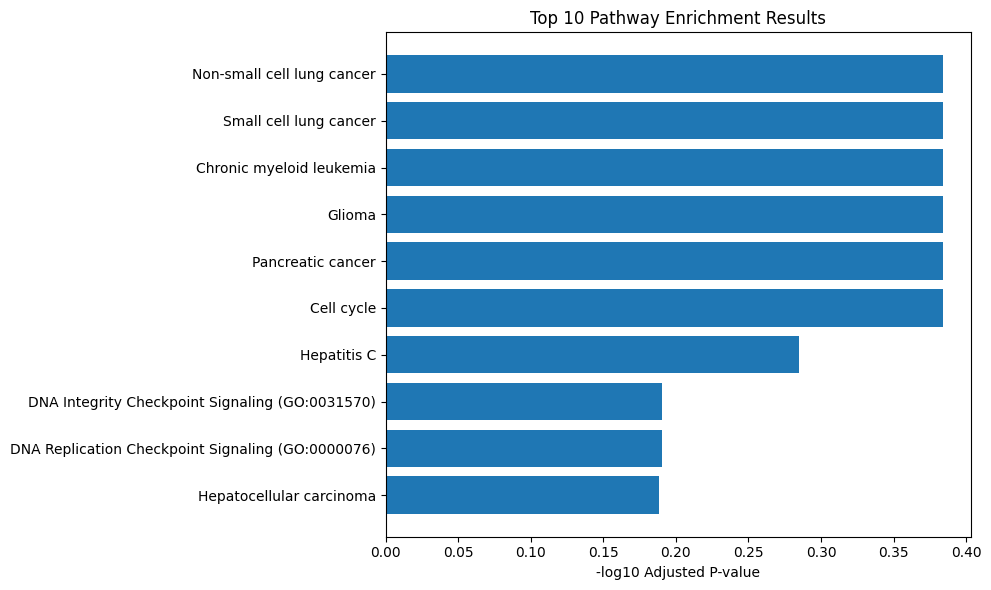

In [9]:
import matplotlib.pyplot as plt
import numpy as np

top = r.head(10).copy()

top["score"] = -np.log10(
    top["Adjusted P-value"].clip(lower=1e-300)
)

plt.figure(figsize=(10, 6))

plt.barh(
    top["Term"].str[:55],
    top["score"]
)

plt.xlabel("-log10 Adjusted P-value")
plt.title("Top 10 Pathway Enrichment Results")

plt.gca().invert_yaxis()
plt.tight_layout()

plt.savefig("pathways.png", dpi=200)
plt.show()

In [10]:
protein_coding_candidates = [
    "FZD9", "IL5RA", "TMEM75", "FFAR4", "TDRD10",
    "ELK1", "EMID1", "SKA1", "GRIK3", "DEFB132",
    "TNNI2", "DLX5", "CCDC170", "ORC1", "CCDC96",
    "KCNQ4"
]

ppi_genes = [
    g for g in genes
    if g in protein_coding_candidates
]

print("Number of genes:", len(ppi_genes))
print("Genes for STRING:")
print("\n".join(ppi_genes))

Number of genes: 16
Genes for STRING:
FZD9
SKA1
KCNQ4
ORC1
DLX5
TNNI2
IL5RA
CCDC170
TMEM75
CCDC96
ELK1
FFAR4
GRIK3
DEFB132
TDRD10
EMID1


In [11]:
import os

for file in os.listdir("/content"):
    if "string_" in file:
        print(file)

string_node_degrees_15_nodes (1).tsv
string_evidence_network_hires_15_nodes (1).png
string_interactions_15_nodes (1).tsv


In [12]:
import pandas as pd
import os

interactions = pd.read_csv(
    "/content/string_interactions_15_nodes (1).tsv",
    sep="\t"
)

node_degrees = pd.read_csv(
    "/content/string_node_degrees_15_nodes (1).tsv",
    sep="\t"
)

print("INTERACTION RESULTS")
display(interactions)

print("NODE DEGREES")
display(node_degrees)

print("Network image exists:",
      os.path.exists("/content/string_evidence_network_hires_15_nodes (1).png"))

INTERACTION RESULTS


,#node1,node2,node1_string_id,node2_string_id,neighborhood_on_chromosome,gene_fusion,phylogenetic_cooccurrence,homology,coexpression,experimentally_determined_interaction,database_annotated,automated_textmining,combined_score
0,CCDC170,CCDC96,9606.ENSP00000239374,9606.ENSP00000309285,0,0,0,0,0,0.095,0,0.368,0.403
1,CCDC96,CCDC170,9606.ENSP00000309285,9606.ENSP00000239374,0,0,0,0,0,0.095,0,0.368,0.403


NODE DEGREES


,#node,identifier,node_degree
0,CCDC170,9606.ENSP00000239374,1
1,CCDC96,9606.ENSP00000309285,1
2,DEFB132,9606.ENSP00000371813,0
3,DLX5,9606.ENSP00000498116,0
4,ELK1,9606.ENSP00000366182,0
5,EMID1,9606.ENSP00000335481,0
6,FFAR4,9606.ENSP00000360538,0
7,FZD9,9606.ENSP00000345785,0
8,GRIK3,9606.ENSP00000362183,0
9,IL5RA,9606.ENSP00000412209,0


Network image exists: True


In [13]:
ppi_summary = pd.DataFrame({
    "Metric": [
        "Organism",
        "Proteins analysed",
        "Unique interaction pairs",
        "Interacting proteins",
        "Combined interaction score",
        "STRING confidence threshold",
        "Proteins with zero connections"
    ],
    "Result": [
        "Homo sapiens",
        15,
        1,
        "CCDC170 - CCDC96",
        0.403,
        0.400,
        13
    ]
})

display(ppi_summary)

ppi_summary.to_csv("ppi_summary.csv", index=False)

print("PPI summary saved successfully!")

,Metric,Result
0,Organism,Homo sapiens
1,Proteins analysed,15
2,Unique interaction pairs,1
3,Interacting proteins,CCDC170 - CCDC96
4,Combined interaction score,0.403
5,STRING confidence threshold,0.4
6,Proteins with zero connections,13


PPI summary saved successfully!
